# Reading a scanned vaccination record with TypeSafe

<a href="https://colab.research.google.com/github/sixhobbits/colab-demo/blob/main/cookbooks/reading_scanned_documents/reading_scanned_documents.ipynb" target="_blank"><img src="https://img.shields.io/badge/Open%20in%20Colab-F9AB00?style=for-the-badge&logo=googlecolab&logoColor=white" alt="Open in Colab" height="28"></a> <a href="https://github.com/sixhobbits/colab-demo/blob/main/cookbooks/reading_scanned_documents/reading_scanned_documents.ipynb" target="_blank"><img src="https://img.shields.io/badge/View%20on%20GitHub-24292F?style=for-the-badge&logo=github&logoColor=white" alt="View on GitHub" height="28"></a>

> **No API key needed.** The code downloads this cookbook's saved answers, so
> *Run all* replays every TypeSafe call from them. It needs no TypeSafe account
> and costs nothing. To call the API yourself, set `TYPESAFE_API_KEY` and
> `DOWNLOAD_CACHE = False`.

From [the docs page](https://console.typesafe.ai/docs/cookbooks/reading_scanned_documents).

You have scanned vaccination records with no text layer, and you want Jev to check that
the information on each one is correct before a trip. Jev takes the image and answers a
set list of questions about it:

- a `Noul` question per vaccine: is it on the record?
- a `Box` question per vaccine: where is its row?
- a `Choice` question per row: what year does the date say, or is it `unreadable`?

![Jev reading a scanned travel vaccination record and flagging two
rows](https://raw.githubusercontent.com/sixhobbits/colab-demo/main/cookbooks/reading_scanned_documents/reading-scanned-documents-hero.gif)

In this example, Jev reads the travel vaccination record above into one row per
vaccine, and flags the rows that need review before the trip. This record has two:

- The rabies date is under a batch sticker, so it can't be read from the scan. Jev
  answers `unreadable` instead of guessing.
- The typhoid dose is from June 2021. The date is clear, but a typhoid injection
  protects for about three years, so it won't cover the trip in November 2026.

In this case we already know the possible answers: the vaccines the clinic gives, and
the years a dose could have been given in. We also have `unreadable` as an option to
account for values that cannot be found on the page.

Two requests read the scan, and a third checks the readings as text. Your code decides
what goes into each request and which rows to flag.

<img src="https://raw.githubusercontent.com/sixhobbits/colab-demo/main/cookbooks/reading_scanned_documents/reading_scanned_documents-diagram-b7e7f0f1fa.png" alt="Diagram" width="1176">

## Setup

```bash
pip install ipython matplotlib 'typesafe-sdk>=0.7.5,<0.8.0' \
    'cooksafe>=0.3.0,<0.4.0'
```

Set `TYPESAFE_API_KEY`.

<Warning> Images and `Box` questions are an early preview. Requests that carry an image
or a `Box` question need the `TypeSafe-Danger-Zone-Images: true` header, and the request
format can change between releases. See [Images](/images). </Warning>

In [ ]:
%pip install -q 'typesafe-sdk>=0.7.5' 'ipython' 'matplotlib' 'cooksafe>=0.3.0,<0.4.0'

In [ ]:
import hashlib
import json
import os
import urllib.request
from datetime import date
from pathlib import Path
from time import perf_counter

import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt
from cooksafe import JsonCache
from IPython.display import Markdown, display
from typesafe_sdk import Image, TypeSafeClient

TYPESAFE_MODEL = "jev-1.14.0"  # the page's model; "jev-latest" runs the newest, live
IMAGES_ON = {"TypeSafe-Danger-Zone-Images": "true"}  # opt in to the image preview
READ_CUTOFF = 0.90  # below this, a person checks the reading against the paper
LEGIBLE_CUTOFF = 0.50  # the legibility Noul gets its own, lower cutoff
IN_DATE_CUTOFF = 0.50  # below this, a nurse checks whether the dose still covers the trip

client = TypeSafeClient(
    api_key=os.environ.get("TYPESAFE_API_KEY", "cache-only"),  # keyless kernels replay
    base_url=os.environ.get("TYPESAFE_ENDPOINT"),
    timeout=120.0,
)


EXAMPLES = (
    "https://raw.githubusercontent.com/typesafe-ai/typesafe-public-examples/main/"
    "cookbooks/reading_scanned_documents"
)


def download(name: str) -> Path:
    """Fetch one of this cookbook's files from typesafe-public-examples unless it is on disk."""
    path = Path(name)
    if not path.exists():
        path.parent.mkdir(parents=True, exist_ok=True)
        urllib.request.urlretrieve(f"{EXAMPLES}/{name}", path)
    return path


CACHE = Path("reading_scanned_documents_cache.json")
# True fills CACHE with the published answers, so the run makes no requests. To run
# live, set it to False and delete CACHE; a CACHE already on disk is never overwritten.
DOWNLOAD_CACHE = True
if DOWNLOAD_CACHE:
    download(CACHE.name)
json_cache = JsonCache(CACHE)

## Send the scan to Jev

![A scanned travel vaccination record](https://raw.githubusercontent.com/sixhobbits/colab-demo/main/cookbooks/reading_scanned_documents/vaccination_record.jpg)

Each request carries the scan in its state as `Image(PAGE)`, under the name `page`, and
each question mentions `page` to say which image it is about. All the questions in a
request see the same image, so each step's questions go in one request.

Jev accepts PNG and JPEG files up to 16 MiB. Each side has to be between 280 and 1568
pixels, so scale a high-resolution scan down before sending it. The
[image limits](/images#limits) page lists the rest, including
limits on the whole request.

In [ ]:
PAGE = download("vaccination_record.jpg")
PAGE_SHA = hashlib.sha256(PAGE.read_bytes()).hexdigest()[:16]  # cache key for the scan


@json_cache
def ask(page_sha: str, questions_json: str, model: str) -> dict:
    """One request: the scan as the state, plus a set of questions about it."""
    started = perf_counter()
    response = client.system_one(
        state={"page": Image(PAGE)},
        questions=json.loads(questions_json),
        model=model,
        extra_headers=IMAGES_ON,
    )
    return {
        "answers": {k: a.model_dump(mode="json") for k, a in response.answers.items()},
        "seconds": round(perf_counter() - started, 2),
        "input_tokens": response.usage.input_tokens or 0,
        "output_tokens": response.usage.output_tokens or 0,
    }


def ask_page(questions: dict) -> dict:
    if not questions:  # nothing to ask, such as a page with no rows found
        return {"answers": {}}
    return ask(PAGE_SHA, json.dumps(questions, sort_keys=True), model=TYPESAFE_MODEL)

## Find which vaccines are on the record

Jev doesn't extract data into a list. It answers questions about what's on the page, so
you ask it about each thing you're looking for. In this case, that's the 16 vaccines the
clinic gives. The first
request asks two questions about each one:

- a `Noul` question: is this vaccine in the table?
- a `Box` question: where is its row?

The list includes vaccines with similar names, like the combined hepatitis A and B
vaccine next to Hepatitis A, to check that Jev matches the exact name.
One more `Noul` question asks whether the table has a vaccine that isn't on the list at
all, since none of the other questions would catch that.

In [ ]:
VACCINES = [
    "Hepatitis A", "Hepatitis B", "Hepatitis A and B combined", "Typhoid",
    "Hepatitis A and typhoid combined", "Yellow fever", "Rabies", "Japanese encephalitis",
    "Tick-borne encephalitis", "Cholera", "MenACWY", "MenB",
    "Tetanus, diphtheria and polio (Td/IPV)", "MMR", "Varicella", "Influenza",
]
PRESENT_CUTOFF = 0.5  # P(recorded) at or above this counts the vaccine as on the page

In [ ]:
def find_questions() -> dict:
    questions = {"unlisted": {
        "type": "noul",
        "instructions": {
            "question": "Does the vaccines table in `page` record any vaccine that is not "
                        "in this list?",
            "list": VACCINES,
        },
    }}
    for i, vaccine in enumerate(VACCINES):
        questions[f"vac_{i:02d}"] = {
            "type": "noul",
            "instructions": f"Is {vaccine} recorded in the vaccines table in `page`, with "
                            "exactly this name?",
        }
        questions[f"vac_{i:02d}|box"] = {
            "type": "box",
            "instructions": f"the whole {vaccine} row of the vaccines table in `page`",
        }
    return questions

All the questions go in one request. Vaccines that score 0.5 or more count as on the page,
and the top edges of their boxes give the page order.

In [ ]:
found = ask_page(find_questions())
F = found["answers"]
present = []
for i, vaccine in enumerate(VACCINES):
    p, box = F[f"vac_{i:02d}"]["noul"], F[f"vac_{i:02d}|box"]
    print(f"{vaccine:<40}recorded {p:.2f}  box top {box['box']['top']:.2f}")
    if p >= PRESENT_CUTOFF:
        present.append({"vaccine": vaccine, "present": p, "box": box["box"],
                        "box_confidence": box["confidence"]})
print(f"\nanother vaccine on the page: {F['unlisted']['noul']:.2f}")

rows = sorted(present, key=lambda r: r["box"]["top"])
for n, row in enumerate(rows, 1):
    row["id"], row["position"] = f"row-{n}", n

Hepatitis A                             recorded 0.98  box top 0.33
Hepatitis B                             recorded 0.98  box top 0.40
Hepatitis A and B combined              recorded 0.02  box top 0.36
Typhoid                                 recorded 0.98  box top 0.48
Hepatitis A and typhoid combined        recorded 0.01  box top 0.34
Yellow fever                            recorded 0.98  box top 0.55
Rabies                                  recorded 0.97  box top 0.69
Japanese encephalitis                   recorded 0.01  box top 0.35
Tick-borne encephalitis                 recorded 0.01  box top 0.34
Cholera                                 recorded 0.01  box top 0.34
MenACWY                                 recorded 0.00  box top 0.34
MenB                                    recorded 0.01  box top 0.35
Tetanus, diphtheria and polio (Td/IPV)  recorded 0.98  box top 0.62
MMR                                     recorded 0.01  box top 0.33
Varicella                               recorded

The six vaccines on the page score 0.97 or more, and the look-alikes score 0.02 or
less. Sorted by their boxes, the six rows come out in the same order as the page. The
question about an unlisted vaccine scores 0.02, so there isn't one.

<Note> A `Box` always returns a box, even for a vaccine that isn't on the page. Only use
the box when the `Noul` says the vaccine is there. </Note>

Sixteen vaccines make 33 questions. With a list of thousands, the questions may not
fit in one request (see [context length](/models#context-length)). A bigger version of
this would narrow the list first, for example with one `Noul` question per group of
vaccines.

## Read the year of each dose

The in-date check only needs to know roughly how old each dose is, so the second request
asks for the year alone, with one `Choice` question per row. A `Choice` always picks one
of its options, so the date under the sticker would otherwise get whichever year looked
closest. The list of years ends with `other` and `unreadable`, which lets Jev say it
can't read the date.

Each row also gets a `Noul` question asking whether the date is fully legible. It's a
second signal, separate from the `Choice`, that something is covering the date.

In [ ]:
YEAR = {
    **{f"y{n}": str(n) for n in range(2016, 2027)},
    "other": "A year before 2016 or after 2026",
    "unreadable": "The year is covered, stained, smudged or damaged and can't be read",
}

The record writes dates as day/month/year, so the year question says the year is the last
part.

In [ ]:
def read_questions(row: dict) -> dict:
    where = f"the DATE GIVEN cell of the {row['vaccine']} row of the vaccines table in `page`"
    i = row["id"]
    return {
        f"{i}|year": {
            "type": "choice", "criteria": YEAR,
            "instructions": "Dates on this record are written day/month/year, so the year "
                            f"is the last part. What year is written in {where}?",
        },
        f"{i}|legible": {
            "type": "noul",
            "instructions": f"Is the date in {where} fully legible, with nothing covering, "
                            "staining, smudging or blurring any of it?",
        },
    }

In [ ]:
read = ask_page({k: q for row in rows for k, q in read_questions(row).items()})
A = read["answers"]
for row in rows:
    i = row["id"]
    row["year"], row["year_confidence"] = A[f"{i}|year"]["choice"], A[f"{i}|year"]["confidence"]
    row["legible"] = A[f"{i}|legible"]["noul"]

An `other` or `unreadable` pick leaves the row without a year, so there's nothing to check
yet.

In [ ]:
UNRESOLVED = ("other", "unreadable")  # picks that leave the row without a year


def year_given(row: dict) -> int | None:
    return None if row["year"] in UNRESOLVED else int(row["year"][1:])


def unresolved(row: dict) -> bool:
    """True when the year came back without a value to check."""
    return year_given(row) is None


def as_text(row: dict) -> str:
    year = year_given(row)
    return str(year) if year else row["year"]


print(f"{'vaccine':<40}{'year':<12}legible")
for row in rows:
    print(f"{row['vaccine']:<40}{as_text(row):<12}{row['legible']:.2f}")

vaccine                                 year        legible
Hepatitis A                             2026        0.96
Hepatitis B                             2026        0.86
Typhoid                                 2021        0.96
Yellow fever                            2025        0.96
Tetanus, diphtheria and polio (Td/IPV)  2024        0.96
Rabies                                  unreadable  0.05


Five years read correctly. For rabies, the `Choice` picks `unreadable` and the legibility
`Noul` is 0.05.

The legibility `Noul` scores the clear dates between 0.86 and 0.96, lower than the
`Choice` answers. That's why it gets its own cutoff of 0.50 further down. The lowest of
them, at 0.86, is the Hepatitis B row with a highlighter stroke across it, still far
above the 0.05 for the date under the sticker.

## Check whether each dose covers the trip

Reading the page correctly doesn't catch the typhoid dose. Its year is clear, and Jev
read it. The third request asks a different question: will this dose still protect the
traveller on the day they leave?

This request doesn't include the image. It sends the readings as text, so the answer is
only about the dose, and the reading stays with the image questions. We work out roughly
how long before departure each dose was given, because date arithmetic is a job for code,
and leave out rows without a year. The state gives Jev the departure date, and the
criteria say what counts as in date.

In [ ]:
DEPARTURE = date(2026, 11, 12)  # from the traveller's booking


def before_departure(year: int) -> str:
    years = DEPARTURE.year - year
    return "less than a year" if years == 0 else f"about {years} year{'s' * (years != 1)}"


CHECK_CONTEXT = (
    "Each entry is one line of an adult traveller's vaccination record, as read from a "
    f"scan. The traveller leaves on {DEPARTURE.day} November {DEPARTURE.year}. Judge "
    "only whether the dose will still protect the traveller on that date, by usual "
    "travel-health guidance for adults."
)
IN_DATE_QUESTION = "Will this dose still protect the traveller on the departure date?"
IN_DATE_CRITERIA = {
    "true": "The dose is within the usual protection period for this vaccine on the "
            "departure date.",
    "false": "The dose is past the usual protection period for this vaccine by the "
             "departure date.",
}

In [ ]:
def check_questions(readable: list[dict]) -> dict:
    return {
        row["id"]: {
            "type": "noul",
            "instructions": {"question": IN_DATE_QUESTION, "entry": row["id"]},
            "criteria": IN_DATE_CRITERIA,
        }
        for row in readable
    }


def check_state(readable: list[dict]) -> dict:
    return {
        "context": CHECK_CONTEXT,
        "entries": [{"id": r["id"], "vaccine": r["vaccine"], "year_given": as_text(r),
                     "given_before_departure": before_departure(year_given(r))}
                    for r in readable],
    }

This request has no image, so it doesn't need the images header.

In [ ]:
@json_cache
def check(state_json: str, questions_json: str, model: str) -> dict:
    started = perf_counter()
    response = client.system_one(
        state=json.loads(state_json), questions=json.loads(questions_json), model=model
    )
    return {
        "answers": {k: a.noul for k, a in response.answers.items()},
        "seconds": round(perf_counter() - started, 2),
        "input_tokens": response.usage.input_tokens or 0,
        "output_tokens": response.usage.output_tokens or 0,
    }


readable = [r for r in rows if not unresolved(r)]
checked = check(json.dumps(check_state(readable)),
                json.dumps(check_questions(readable)),
                model=TYPESAFE_MODEL) if readable else {"answers": {}}
for row in rows:
    row["in_date"] = checked["answers"].get(row["id"])
    year = year_given(row)
    ago = before_departure(year) if year else "-"
    shown = "  -" if row["in_date"] is None else f"{row['in_date']:.2f}"
    print(f"{row['vaccine']:<40}{as_text(row):<12}{ago:<20}{shown}")

Hepatitis A                             2026        less than a year    0.94
Hepatitis B                             2026        less than a year    0.83
Typhoid                                 2021        about 5 years       0.38
Yellow fever                            2025        about 1 year        0.95
Tetanus, diphtheria and polio (Td/IPV)  2024        about 2 years       0.93
Rabies                                  unreadable  -                     -


Typhoid, given about 5 years before departure, scores 0.38. The other doses score 0.83
or more. Rabies has no score because its year couldn't be read.

## Flag the rows to check

A row gets up to two flags:

- **Check the reading** if an answer about finding or reading the row is below 0.90, the
  legibility `Noul` is below 0.50, or the year came back `other` or `unreadable`.
- **Check the dose** if the in-date score is below 0.50.

The whole page is flagged if the question about an unlisted vaccine scores 0.5 or more,
since that vaccine has no row of its own.

A high in-date score doesn't cancel a doubtful reading, because it was judged on a year
that might be wrong. The cutoffs (`READ_CUTOFF` at 0.90, `LEGIBLE_CUTOFF` and
`IN_DATE_CUTOFF` at 0.50) are a starting point. Tune them on records a person has
already checked.

In [ ]:
def reading_score(row: dict) -> float:
    """The weakest of the answers that say the row was found and read."""
    return min(row["present"], row["year_confidence"])


def review_reasons(row: dict) -> list[str]:
    reasons = []
    if (unresolved(row) or reading_score(row) < READ_CUTOFF
            or row["legible"] < LEGIBLE_CUTOFF):
        reasons.append("Check the reading")
    if row["in_date"] is not None and row["in_date"] < IN_DATE_CUTOFF:
        reasons.append("Check the dose")
    return reasons


def review_queue(rows: list[dict]) -> list[tuple[dict, list[str]]]:
    return [(row, review_reasons(row)) for row in rows if review_reasons(row)]


def page_reasons() -> list[str]:
    """Flags that belong to the whole page rather than to one row."""
    if F["unlisted"]["noul"] >= PRESENT_CUTOFF:
        return ["Check the page: it may record a vaccine outside the list"]
    return []


table = ["| Vaccine | Year given | Lowest reading score | Legible | In date | Flagged |",
         "|---|---|---|---|---|---|"]
for row in rows:
    in_date = "–" if row["in_date"] is None else f"{row['in_date']:.2f}"
    table.append(f"| {row['vaccine']} | {as_text(row)} | {reading_score(row):.2f} | "
                 f"{row['legible']:.2f} | {in_date} | {', '.join(review_reasons(row)) or '–'} |")
display(Markdown("\n".join(table)))
print(f"page: {', '.join(page_reasons()) or 'not flagged'} "
      f"(another vaccine on the page: {F['unlisted']['noul']:.2f})")

page: not flagged (another vaccine on the page: 0.02)


| Vaccine | Year given | Lowest reading score | Legible | In date | Flagged |
|---|---|---|---|---|---|
| Hepatitis A | 2026 | 0.98 | 0.96 | 0.94 | – |
| Hepatitis B | 2026 | 0.98 | 0.86 | 0.83 | – |
| Typhoid | 2021 | 0.98 | 0.96 | 0.38 | Check the dose |
| Yellow fever | 2025 | 0.98 | 0.96 | 0.95 | – |
| Tetanus, diphtheria and polio (Td/IPV) | 2024 | 0.98 | 0.96 | 0.93 | – |
| Rabies | unreadable | 0.97 | 0.05 | – | Check the reading |

## Crop the flagged rows for the nurse

A `Box` answer has `top`, `bottom`, `left` and `right` edges as fractions of the image's
height and width, plus a `confidence`. Multiply by the image size to get pixels. The
crops reuse the boxes from the first request with a small margin, and a wider margin when
the box's confidence is below 0.6.

In [ ]:
SURFACE, INK, INK2, MUTED = "#fcfcfb", "#0b0b0b", "#52514e", "#898781"
GRID, AXIS, BLUE, ORANGE = "#e1e0d9", "#c3c2b7", "#2a78d6", "#eb6834"
PAD = 0.02  # fraction of the page added around each box before cropping
LOW_BOX_CONFIDENCE, LOW_PAD = 0.6, 0.05  # a less certain box gets a wider margin


def crop(box: dict, confidence: float):
    page = plt.imread(PAGE)
    h, w = page.shape[:2]
    pad = LOW_PAD if confidence < LOW_BOX_CONFIDENCE else PAD
    top, bottom = max(0.0, box["top"] - pad), min(1.0, box["bottom"] + pad)
    left, right = max(0.0, box["left"] - pad), min(1.0, box["right"] + pad)
    return page[int(top * h):int(bottom * h), int(left * w):int(right * w)]

Typhoid                                 top 0.48  bottom 0.53  left 0.06  right 0.94  confidence 0.88
Rabies                                  top 0.69  bottom 0.75  left 0.04  right 0.94  confidence 0.77


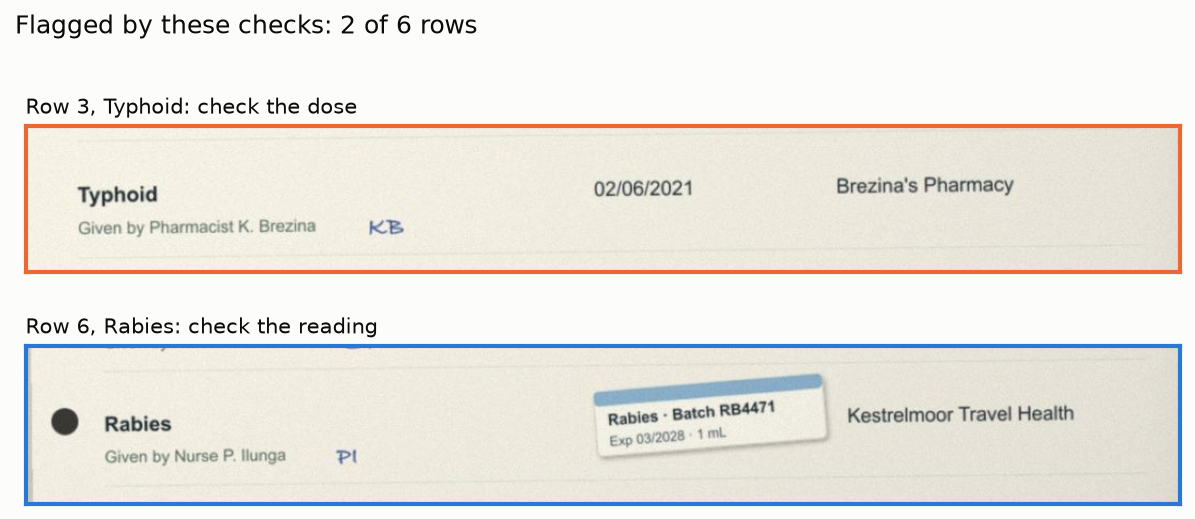

In [ ]:
queue = review_queue(rows)
for row, _ in queue:
    b = row["box"]
    print(f"{row['vaccine']:<40}top {b['top']:.2f}  bottom {b['bottom']:.2f}  "
          f"left {b['left']:.2f}  right {b['right']:.2f}  "
          f"confidence {row['box_confidence']:.2f}")

if not queue:
    print("No rows were flagged by these checks.")
else:
    fig, axes = plt.subplots(len(queue), 1, figsize=(8, 1.9 * len(queue)), facecolor=SURFACE,
                             squeeze=False)
    for ax, (row, reasons) in zip(axes[:, 0], queue):
        ax.imshow(crop(row["box"], row["box_confidence"]))
        ax.set_xticks([]), ax.set_yticks([])
        for side in ax.spines.values():
            side.set_color(ORANGE if "Check the dose" in reasons else BLUE)
            side.set_linewidth(2)
        ax.set_title(f"Row {row['position']}, {row['vaccine']}: "
                     f"{', '.join(reasons).lower()}", loc="left", color=INK, fontsize=10)
    fig.suptitle(f"Flagged by these checks: {len(queue)} of {len(rows)} rows",
                 x=0.01, ha="left", color=INK, fontsize=12)
    plt.tight_layout()
    display(fig)
    plt.close(fig)

Typhoid is flagged to check the dose, and Rabies to check the reading. Each crop shows
the whole row.

## Using it on your own documents

This approach fits any document where you know the possible answers in advance. Swap in
your own lists for `VACCINES` and `YEAR`, keep `other` and `unreadable` in each list of
options, and rewrite the in-date question for your documents.

----------------

# Appendix

## Why reading and checking are separate requests

Skip the text-only request and ask the in-date question about the scan itself, with the
departure date in the header.

In [ ]:
def direct_questions(row: dict) -> dict:
    return {row["id"]: {
        "type": "noul",
        "instructions": {"question": IN_DATE_QUESTION + " The departure date is on `page`.",
                         "entry": f"the {row['vaccine']} row of the vaccines table in "
                                  "`page`"},
        "criteria": IN_DATE_CRITERIA,
    }}


direct = ask_page({k: q for row in rows for k, q in direct_questions(row).items()})
print(f"{'vaccine':<40}{'from the image':>15}{'from the readings':>19}")
for row in rows:
    via_text = "  -" if row["in_date"] is None else f"{row['in_date']:.2f}"
    print(f"{row['vaccine']:<40}{direct['answers'][row['id']]['noul']:>15.2f}{via_text:>19}")

vaccine                                  from the image  from the readings
Hepatitis A                                        0.88               0.94
Hepatitis B                                        0.85               0.83
Typhoid                                            0.50               0.38
Yellow fever                                       0.96               0.95
Tetanus, diphtheria and polio (Td/IPV)             0.84               0.93
Rabies                                             0.88                  -


Rabies scores 0.88 and passes, with its date under a sticker. Typhoid scores 0.50,
right on the cutoff, so it passes too. Both misses come from one answer covering two
steps: you can't tell whether Jev failed to read the date or judged the dose wrongly.